In [105]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn import metrics

In [106]:
medical_data = pd.read_csv('datasets/insurance.csv')

In [107]:
medical_data.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [108]:
medical_data.shape

(1338, 7)

In [109]:
medical_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


In [110]:
medical_data.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


### Catagorical Feature
- sex
- region
- smoker

c:\Users\PMYLS\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


Text(0.5, 1.0, 'Age Distribution')

<Figure size 600x600 with 0 Axes>

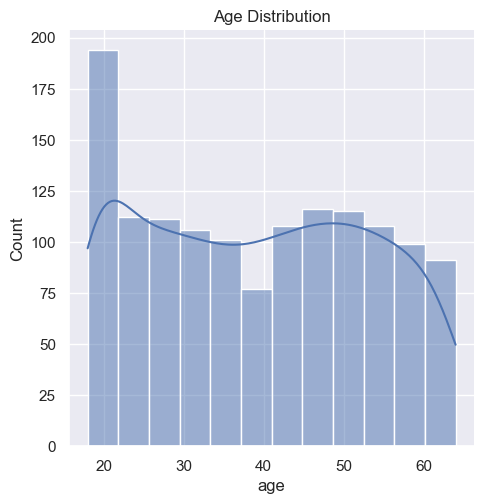

In [111]:
# distribution of age 

sns.set()
plt.figure(figsize=(6,6))
sns.displot(medical_data['age'],kde=True)
plt.title('Age Distribution')

Text(0.5, 1.0, 'Gender distribution')

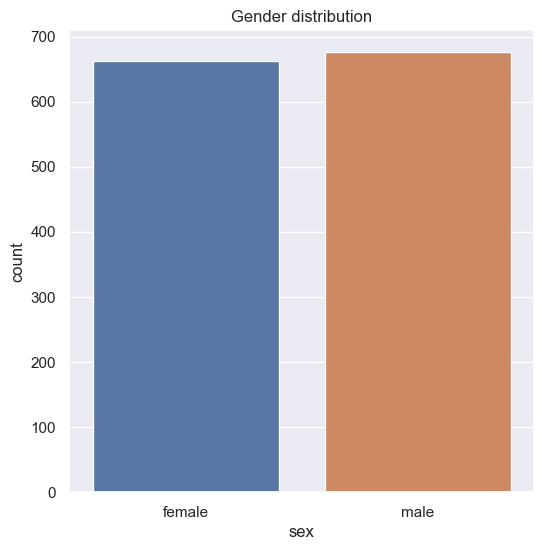

In [112]:
# plot catagorical feature
plt.figure(figsize=(6,6))
sns.countplot(x='sex',data=medical_data)
plt.title('Gender distribution')

c:\Users\PMYLS\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


Text(0.5, 1.0, 'Bmi Distribution')

<Figure size 600x600 with 0 Axes>

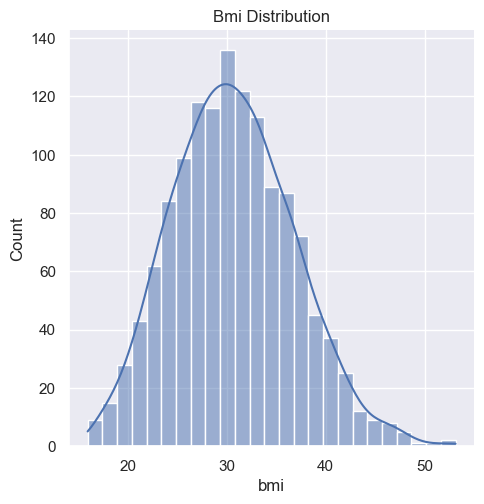

In [113]:

plt.figure(figsize=(6,6))
sns.displot(medical_data['bmi'],kde=True)
plt.title('Bmi Distribution')

#### Normal BMI Range  ---> 18.5 to 24.5

Text(0.5, 1.0, 'children distribution')

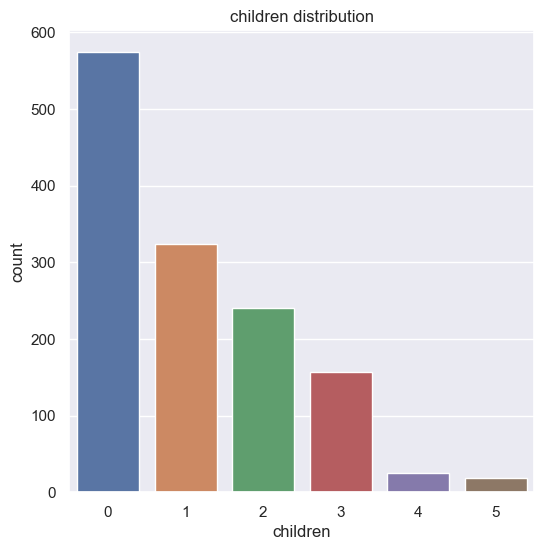

In [114]:
plt.figure(figsize=(6,6))
sns.countplot(x='children',data=medical_data)
plt.title("children distribution")

Text(0.5, 1.0, 'smoker distribution')

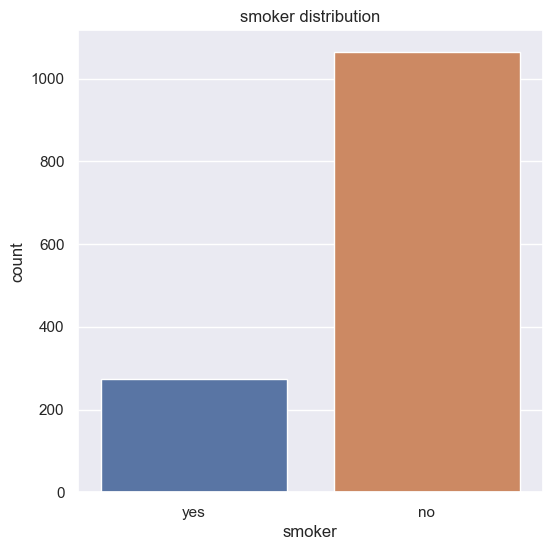

In [115]:
plt.figure(figsize=(6,6))
sns.countplot(x='smoker',data=medical_data)
plt.title("smoker distribution")

Text(0.5, 1.0, 'Region distribution')

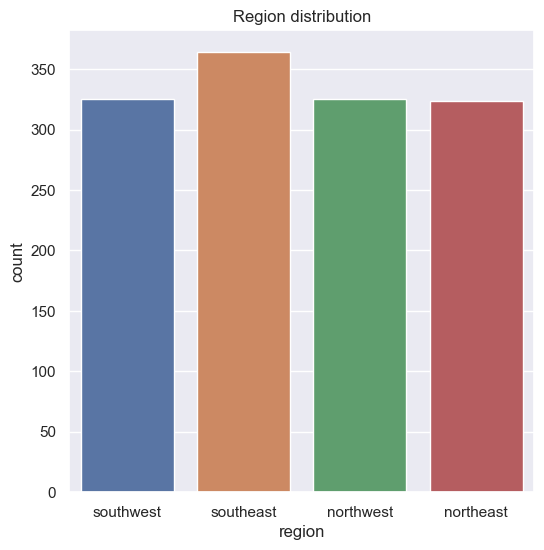

In [116]:
plt.figure(figsize=(6,6))
sns.countplot(x='region',data=medical_data)
plt.title("Region distribution")

c:\Users\PMYLS\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


Text(0.5, 1.0, 'Charge Distribution')

<Figure size 600x600 with 0 Axes>

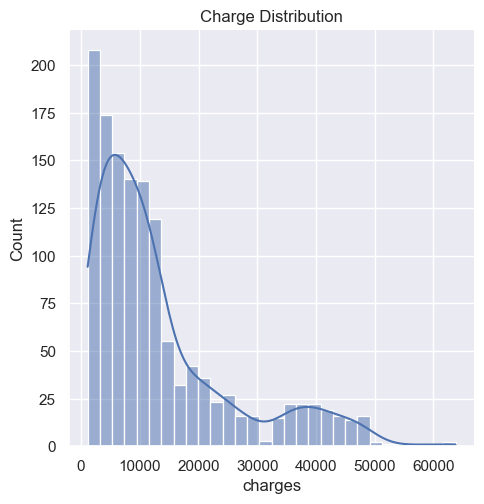

In [117]:
plt.figure(figsize=(6,6))
sns.displot(medical_data['charges'],kde=True)
plt.title('Charge Distribution')

### Data Preprocessing

##### Encoding catagorical feature

In [118]:
medical_data['sex']=medical_data['sex'].map({'male':0,'female':1})
medical_data['smoker']=medical_data['smoker'].map({'no':0,'yes':1})
medical_data['region']=medical_data["region"].map({'southwest':0, 'southeast':1, 'northwest':2, 'northeast':3})

In [119]:
medical_data['region'].unique()

array([0, 1, 2, 3], dtype=int64)

In [120]:
medical_data.head()

,age,sex,bmi,children,smoker,region,charges
0,19,1,27.900,0,1,0,16884.92400
1,18,0,33.770,1,0,1,1725.55230
2,28,0,33.000,3,0,1,4449.46200
3,33,0,22.705,0,0,2,21984.47061
4,32,0,28.880,0,0,2,3866.85520


In [122]:
x=medical_data.drop(columns=['charges'],axis=1)
y=medical_data['charges']

In [125]:
y.head()

0    16884.92400
1     1725.55230
2     4449.46200
3    21984.47061
4     3866.85520
Name: charges, dtype: float64

In [126]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.20,random_state=2)

In [127]:
print(x_train.shape,x_test.shape,y_train.shape,y_test.shape)

(1070, 6) (268, 6) (1070,) (268,)


In [128]:
model= LinearRegression()
model.fit(x_train,y_train)

LinearRegression()

In [129]:
pred= model.predict(x_train)
score_train = metrics.r2_score(y_train,pred)
score_train

0.7519923667088932

In [130]:
pred_test= model.predict(x_test)
score_test = metrics.r2_score(y_test,pred_test)
score_test

0.7445422986536503